# Spatial Search on 2D Quantum Walk

Flip-flop coined quantum walk on the $2$-dimensional periodic square lattice with $N = L^2$ nodes.

Coin states: $|0\rangle: -x$, $|1\rangle: +x$, $|2\rangle: -y$, $|3\rangle: +y$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from classiq import *

/Users/reisato/PycharmProjects/pythonProject1/.venv/lib/python3.11/site-packages/classiq/__init__.py:110: UserWarning: 'nest_asyncio2' is not installed; falling back to the legacy 'nest_asyncio'. 'nest_asyncio2' ships with modern Jupyter (ipykernel >= 7.3); consider upgrading your Jupyter installation, for example: pip install --upgrade jupyter ipykernel
  enable_jupyter_notebook()


In [2]:
d = 2
L = 2**4
N = L**d
k = 2 * d
nx = int(np.ceil(np.log2(L)))
nl = int(np.ceil(np.log2(k)))
NUM_SAMPLES = 1000
print("N =", N, "nx =", nx, "nl =", nl)

N = 256 nx = 4 nl = 2


# Quantum circuit

In [3]:
class pos_reg(QStruct):
    x: QNum[nx]
    y: QNum[nx]


@qfunc
def prepare_pos_state(pos: pos_reg):
    hadamard_transform(pos)


@qfunc
def prepare_coin_state(l: QNum[nl]):
    hadamard_transform(l)


@qfunc
def initial_state(pos: pos_reg, l: QNum):
    prepare_pos_state(pos)
    prepare_coin_state(l)


@qperm
def oracle_operator(pos: pos_reg):
    control((pos.x == L // 2) & (pos.y == L // 2), lambda: phase(np.pi))


@qfunc
def coin_operator(l: QNum):
    grover_diffuser(lambda psi: prepare_coin_state(psi), l)


@qfunc
def shift_plus(p: QNum):
    p += 1


@qfunc
def shift_minus(p: QNum):
    p += -1


@qfunc
def move_operator(pos: pos_reg, l: QNum):
    control(l == 0, lambda: shift_minus(pos.x))
    control(l == 1, lambda: shift_plus(pos.x))
    control(l == 2, lambda: shift_minus(pos.y))
    control(l == 3, lambda: shift_plus(pos.y))


@qfunc
def flip_operator(l: QArray):
    X(l[0])


@qfunc
def shift_operator(pos: pos_reg, l: QNum):
    move_operator(pos, l)
    flip_operator(l)


@qfunc
def quantum_walk(pos: pos_reg, l: QNum):
    coin_operator(l)
    shift_operator(pos, l)


@qfunc
def coin_walk(t: CInt, pos: pos_reg, l: QNum):
    power(t, lambda: [oracle_operator(pos), quantum_walk(pos, l)])


@qfunc
def main(t: CInt, p: Output[pos_reg]):
    l = QNum()
    allocate(p.size, p)
    allocate(nl, l)
    initial_state(p, l)
    coin_walk(t, p, l)
    drop(l)

In [4]:
qprog = synthesize(main)
print("width =", qprog.data.width)

width = 11


# Exact simulation

In [5]:
def exact_mark_prob(d, L, itr):
    k = 2 * d
    mark = (L // 2,) * d
    C = np.ones((k, k)) * (2.0 / k) - np.eye(k)
    psi = np.ones((L,) * d + (k,)) / np.sqrt(L**d * k)
    mark_prob = []
    for t in range(itr):
        if t > 0:
            psi[mark] *= -1
            psi_coin = psi @ C.T
            next_psi = np.zeros_like(psi)
            for i in range(d):
                next_psi[..., 2 * i + 1] = np.roll(psi_coin[..., 2 * i], +1, axis=i)
                next_psi[..., 2 * i] = np.roll(psi_coin[..., 2 * i + 1], -1, axis=i)
            psi = next_psi
        mark_prob.append(np.sum(psi[mark] ** 2))
    return np.array(mark_prob)


itr = 100
mark_prob = exact_mark_prob(d, L, itr)
print(f"Peak probability: {mark_prob.max():.4f} at t={mark_prob.argmax()}")

Peak probability: 0.2698 at t=74


# Circuit simulation

In [6]:
t_list = [0, 10, 15, 20, 30, 35, 40, 50, 60, 70, 80, 85, 90]
circuit_prob = []

exec_pref = ExecutionPreferences(num_shots=NUM_SAMPLES)
with ExecutionSession(qprog, execution_preferences=exec_pref) as es:
    for t in t_list:
        df = es.sample({"t": t}).dataframe
        circuit_prob.append(df.loc[(df["p.x"] == L // 2) & (df["p.y"] == L // 2), "probability"].sum())
        print(f"t={t}: P(x0)={circuit_prob[-1]:.3f}")

t=0: P(x0)=0.002


t=10: P(x0)=0.085


t=15: P(x0)=0.142


t=20: P(x0)=0.242


t=30: P(x0)=0.217


t=35: P(x0)=0.158


... (3 outputs left out)

t=70: P(x0)=0.233


t=80: P(x0)=0.231


t=85: P(x0)=0.157


t=90: P(x0)=0.060


In [7]:
exact_at_t = mark_prob[t_list]
comparison = pd.DataFrame({
    "t": t_list,
    "exact": exact_at_t,
    "circuit": circuit_prob,
    "abs_diff": np.abs(np.array(circuit_prob) - exact_at_t),
    "shot_noise_1sigma": np.sqrt(exact_at_t * (1 - exact_at_t) / NUM_SAMPLES),
})
comparison.to_csv("comparison_d2.csv", index=False)
comparison.round(4)

,t,exact,circuit,abs_diff,shot_noise_1sigma
0,0,0.0039,0.002,0.0019,0.0020
1,10,0.0916,0.085,0.0066,0.0091
2,15,0.1454,0.142,0.0034,0.0111
3,20,0.2389,0.242,0.0031,0.0135
4,30,0.2257,0.217,0.0087,0.0132
5,35,0.1528,0.158,0.0052,0.0114
6,40,0.0663,0.067,0.0007,0.0079
7,50,0.0000,0.000,0.0000,0.0002
8,60,0.0962,0.092,0.0042,0.0093
9,70,0.2253,0.233,0.0077,0.0132


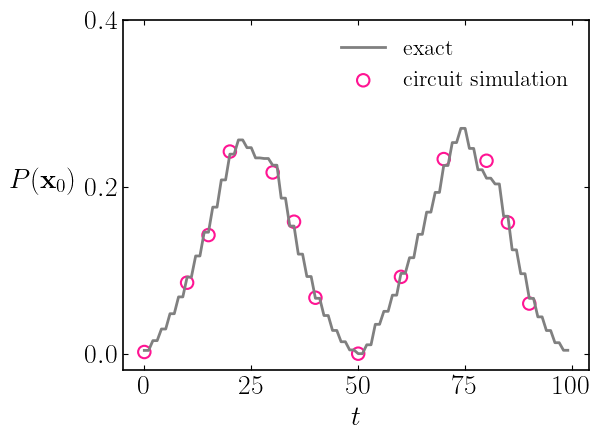

In [8]:
plt.rcParams.update({
    "font.size": 20,
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 1.2,
})

plt.plot(range(itr), mark_prob, linewidth=2.0, color="gray", label=r"$\rm exact$")
plt.scatter(t_list, circuit_prob, facecolors="none", edgecolors="deeppink", linewidths=1.5, s=80,
            label=r"$\rm circuit\ simulation$")
plt.legend(loc="upper right", fontsize=16, frameon=False)
plt.ylim([-0.02, 0.4])
plt.yticks([0.0, 0.2, 0.4])
plt.xlabel(r"$t$")
plt.ylabel(r"$P({\bf x}_0)$", rotation=0, labelpad=30)
plt.tick_params(which="both", top=True, bottom=True, left=True, right=True, direction="in")
plt.tight_layout()
plt.savefig("ss_search_d2_circuit.png")
plt.show()

## Reference

https://arxiv.org/pdf/1010.4705